# Comparing Resampling Methods and Fairness

## Phase 3 Exploratory Data Analysis

### Research question

How do different resampling methods affect predictive performance and fairness across demographic groups in an imbalanced classification problem?

This project uses the Adult Income dataset and a decision tree classifier to compare four conditions: no resampling (the control), random oversampling, SMOTE-NC, and random undersampling. We will examine accuracy, precision, recall, and F1, along with differences in model outcomes between demographic groups. This exploratory analysis will examine data quality, class and demographic group counts, and relationships among variables to prepare for Phase 4 modeling.

### Outcome and protected groups

The target is income, and the favorable outcome is **income >50K**. The other outcome is **income <=50K**.

Sex is the protected attribute, with **male designated privileged** and **female designated unprivileged** for fairness evaluation. These definitions use the dataset's recorded `Male` and `Female` categories. We will report female-minus-male gaps for statistical parity and equal opportunity during model evaluation.

Underrepresentation describes the number of examples in a subgroup; unprivileged describes a demographic group used as the disadvantaged reference in fairness evaluation. We will examine four sex/income subgroups:

- Female with income <=50K
- Female with income >50K
- Male with income <=50K
- Male with income >50K

Sampling targets will depend on these subgroups' counts in each training fold, not on privileged or unprivileged status. Either demographic group may have subgroups resampled; female status alone does not determine underrepresentation.

### Dataset
The dataset was downloaded from https://archive.ics.uci.edu/dataset/2/adult. This is the same dataset used by our chosen research article: Zhou, Kantarcioglu, & Clifton (2023), "On Improving Fairness of AI Models with Synthetic Minority Oversampling Techniques"


### Inspect the raw files

Before preparing the data, we inspect the files directly and read the supplied documentation to identify the field names and loading requirements.


In [1]:
from pathlib import Path

DATA_DIR = Path("data")
for filename in ["adult.data", "adult.test"]:
    print(f"\n{filename}: first three lines")
    with (DATA_DIR / filename).open() as file:
        for _ in range(3):
            print(file.readline().rstrip())

print("\nadult.names: dataset documentation")
print((DATA_DIR / "adult.names").read_text())



adult.data: first three lines
39, State-gov, 77516, Bachelors, 13, Never-married, Adm-clerical, Not-in-family, White, Male, 2174, 0, 40, United-States, <=50K
50, Self-emp-not-inc, 83311, Bachelors, 13, Married-civ-spouse, Exec-managerial, Husband, White, Male, 0, 0, 13, United-States, <=50K
38, Private, 215646, HS-grad, 9, Divorced, Handlers-cleaners, Not-in-family, White, Male, 0, 0, 40, United-States, <=50K

adult.test: first three lines
|1x3 Cross validator
25, Private, 226802, 11th, 7, Never-married, Machine-op-inspct, Own-child, Black, Male, 0, 0, 40, United-States, <=50K.
38, Private, 89814, HS-grad, 9, Married-civ-spouse, Farming-fishing, Husband, White, Male, 0, 0, 50, United-States, <=50K.

adult.names: dataset documentation
| This data was extracted from the census bureau database found at
| http://www.census.gov/ftp/pub/DES/www/welcome.html
| Donor: Ronny Kohavi and Barry Becker,
|        Data Mining and Visualization
|        Silicon Graphics.
|        e-mail: ronnyk@sgi.c

### Load and inspect the observations

Using the field order in `adult.names`, we assign column names because the data files have no header. We skip the first metadata line in `adult.test` and ignore spaces immediately after delimiters. We keep the two source DataFrames for separate inspection and combine them for an overall view. The documentation says that `Unknown` values were converted to "?". At this stage, we leave `?` and the income labels as loaded so that the inspection shows their original values.


In [2]:
import pandas as pd

columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income"
]

adult_train = pd.read_csv(
    "data/adult.data",
    header=None,
    names=columns,
    skipinitialspace=True
)

adult_test = pd.read_csv(
    "data/adult.test",
    header=None,
    names=columns,
    skipinitialspace=True,
    skiprows=1
)

df = pd.concat(
    [adult_train, adult_test],
    ignore_index=True
)

In [3]:
for name, data in [("Training", adult_train), ("Test", adult_test), ("Combined", df)]:
    print(f"\n{name} data: {data.shape[0]:,} rows, {data.shape[1]} columns")
    display(data.head())

print("\nCombined dataset structure")
df.info()

display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values_including_missing": df.nunique(dropna=False),
    "missing_values_recognized_by_pandas": df.isna().sum(),
    "question_mark_values": df.eq("?").sum()
}))



Training data: 32,561 rows, 15 columns


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Test data: 16,281 rows, 15 columns


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K.
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K.
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K.
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K.
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K.



Combined data: 48,842 rows, 15 columns


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Combined dataset structure
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


,dtype,unique_values_including_missing,missing_values_recognized_by_pandas,question_mark_values
age,int64,74,0,0
workclass,str,9,0,2799
fnlwgt,int64,28523,0,0
education,str,16,0,0
education_num,int64,16,0,0
marital_status,str,7,0,0
occupation,str,15,0,2809
relationship,str,6,0,0
race,str,5,0,0
sex,str,2,0,0


### Inspect the values in each column

We display every distinct categorical value and its count separately for training and test data. For numerical columns, we show descriptive statistics and a sorted sample of distinct values; the unique-value counts above indicate how many distinct values exist in total.


In [4]:
for column in df.select_dtypes(include="number").columns:
    print(f"\n{column}: numerical summary")
    with pd.option_context("display.float_format", lambda value: f"{value:.3f}".rstrip("0").rstrip(".")):
        display(df[column].describe().to_frame(name=column))

for column in df.select_dtypes(exclude="number").columns:
    print(f"\n{column}: all distinct values and counts by source file")
    counts = pd.concat({
        "training_count": adult_train[column].value_counts(dropna=False),
        "test_count": adult_test[column].value_counts(dropna=False)
    }, axis=1).fillna(0).astype(int)
    with pd.option_context("display.max_rows", None):
        display(counts)



age: numerical summary


,age
count,48842
mean,38.644
std,13.711
min,17
25%,28
50%,37
75%,48
max,90



fnlwgt: numerical summary


,fnlwgt
count,48842
mean,189664.135
std,105604.025
min,12285
25%,117550.5
50%,178144.5
75%,237642
max,1490400



education_num: numerical summary


...

,training_count,test_count
sex,,
Male,21790,10860
Female,10771,5421



native_country: all distinct values and counts by source file


,training_count,test_count
native_country,,
United-States,29170,14662
Mexico,643,308
?,583,274
Philippines,198,97
Germany,137,69
Canada,121,61
Puerto-Rico,114,70
El-Salvador,106,49
India,100,51



income: all distinct values and counts by source file


,training_count,test_count
income,,
<=50K,24720,0
>50K,7841,0
<=50K.,0,12435
>50K.,0,3846


### Column meanings and feature types

The following names match the Python column names used above. Underscores replace the hyphens used in the raw documentation, such as `education-num` becoming `education_num`. These are conceptual feature types; the loaded Python data types are displayed above.

| Column | Feature type | Meaning and role |
| --- | --- | --- |
| `age` | Numerical, integer | Age in years. |
| `workclass` | Categorical, nominal | Employment category, such as `Private`, `Self-emp-not-inc`, or `State-gov`. |
| `fnlwgt` | Numerical, integer | Final census sample weight. It represents how many people in the population a sampled record represents; it is not an individual's income. Its role in modeling or weighting will require an explicit decision. |
| `education` | Categorical, ordered | Highest education category, such as `HS-grad`, `Bachelors`, or `Masters`. |
| `education_num` | Numerical, ordinal code | Ordered numerical representation of education level. It overlaps with `education`; we will examine their relationship before choosing modeling inputs. |
| `marital_status` | Categorical, nominal | Marital status, such as `Never-married`, `Married-civ-spouse`, or `Divorced`. |
| `occupation` | Categorical, nominal | Occupational category, such as `Sales`, `Craft-repair`, or `Prof-specialty`. |
| `relationship` | Categorical, nominal | Household relationship category, such as `Husband`, `Wife`, or `Own-child`. |
| `race` | Categorical, nominal | Recorded race category. Sex is the protected attribute selected for this project's fairness comparisons. |
| `sex` | Categorical, binary | Recorded `Female` or `Male` category. Protected attribute: female is designated unprivileged and male privileged. |
| `capital_gain` | Numerical, integer | Recorded capital gain amount. |
| `capital_loss` | Numerical, integer | Recorded capital loss amount. |
| `hours_per_week` | Numerical, integer | Reported hours worked per week. |
| `native_country` | Categorical, nominal | Recorded country of origin category. |
| `income` | Categorical, binary target | Income category, intended as `<=50K` or `>50K`. The raw test labels include trailing periods, as shown above; these will need normalization. Income `>50K` is the favorable outcome. |

These descriptions follow the local `adult.names` documentation.

#### Findings from the initial inspection

The displayed shapes show 32,561 training observations and 16,281 test observations, giving 48,842 observations and 15 columns in the combined data. The loaded types are six integer columns and nine object columns. The object columns contain categorical labels, including the income target; an integer storage type does not by itself mean a feature is continuous, as illustrated by the ordered `education_num` code.

**Unknown values and label consistency.** Pandas reports no recognized missing values at this stage, but the explicit `?` check finds unknown values in `workclass` (2,799), `occupation` (2,809), and `native_country` (857). These are counts of entries per column; one row may have unknown values in more than one column. The counts show why checking only `isna()` would miss true missing values. We will need to recognize these markers as missing before deciding how to handle them. The income frequency table also shows four raw strings instead of the intended two outcome categories: `<=50K` and `>50K` in training, and `<=50K.` and `>50K.` in test. The trailing periods need to be standardized before analyzing the combined outcome distribution.

**Numerical ranges and values to investigate.** The following observations come from the numerical summaries above. Extreme values are candidates for further examination.

| Feature | Observed minimum | Observed maximum | Interpretation and follow-up |
| --- | ---: | ---: | --- |
| `age` | 17 | 90 | The median is 37 and the middle half spans 28–48. Ages near 90 are far above the upper quartile and warrant a closer look at their frequency and distribution. |
| `fnlwgt` | 12,285 | 1,490,400 | The median is 178,144.5 and the upper quartile is 237,642. The large maximum suggests a long upper tail to examine. This variable is a census sample weight, so large values require interpretation in that context. |
| `education_num` | 1 | 16 | There are 16 distinct codes, matching the number of education categories. We should check their mapping before deciding whether both education columns are needed. |
| `capital_gain` | 0 | 99,999 | The first quartile, median, and third quartile are all zero, while the mean is 1,079.068. This indicates a concentration at zero with a high positive upper tail. We should examine nonzero values and the frequency of the maximum. |
| `capital_loss` | 0 | 4,356 | All three quartiles are zero, while the mean is 87.502. As with capital gain, the nonzero values need separate attention because an overall summary is dominated by zeros. |
| `hours_per_week` | 1 | 99 | The median is 40 and the middle half spans 40–45 hours. Both 1 and 99 are far from typical reported hours. |

**Categorical imbalance and rare values.** The sex frequency table contains 32,650 male and 16,192 female observations, so the two demographic groups have unequal representation. This does not yet tell us which sex/income subgroups are smallest, which would require a cross-tabulation after normalizing income labels. The categorical tables also show substantial imbalance within predictors: `Private` is the largest workclass category and `United-States` is the largest native-country category. Some categories are very rare: `Never-worked` has 10 observations, `Armed-Forces` has 15, and `Holand-Netherlands` has one training observation and none in test. Rare categories may be absent from individual folds, which will matter when preparing categorical encoding. We should retain the documented category labels unless a later, justified preparation step changes them.


### Sex/income subgroup counts and missing values

The table and chart show the four sex/income subgroup sizes. We also count rows containing `?` (an unknown value) and how many would remain if we dropped those rows.

We use a copy of the combined data and remove the trailing periods from the test income labels so the same income categories are counted together. The original data are unchanged.


In [5]:
# Make a copy and match the training and test income labels.
subgroup_data = df.copy()
subgroup_data["income"] = subgroup_data["income"].str.rstrip(".")

# Mark rows that contain at least one unknown value.
missing_rows = subgroup_data.eq("?").any(axis=1)

# Count all rows and rows with unknown values in each subgroup.
subgroup_counts = subgroup_data.groupby(["sex", "income"]).size()
missing_counts = subgroup_data[missing_rows].groupby(["sex", "income"]).size()

summary = pd.DataFrame({
    "Total rows": subgroup_counts,
    "Rows with missing values": missing_counts
}).fillna(0).astype(int)
summary["Rows left if dropped"] = summary["Total rows"] - summary["Rows with missing values"]
display(summary)

print("Total rows:", len(subgroup_data))
print("Rows with missing values:", missing_rows.sum())
print("Rows left if dropped:", len(subgroup_data) - missing_rows.sum())


Total rows  Rows with missing values  Rows left if dropped
sex    income                                                            
Female <=50K        14423                      1397                 13026
       >50K          1769                       100                  1669
Male   <=50K        22732                      1744                 20988
       >50K          9918                       379                  9539

Total rows: 48842
Rows with missing values: 3620
Rows left if dropped: 45222


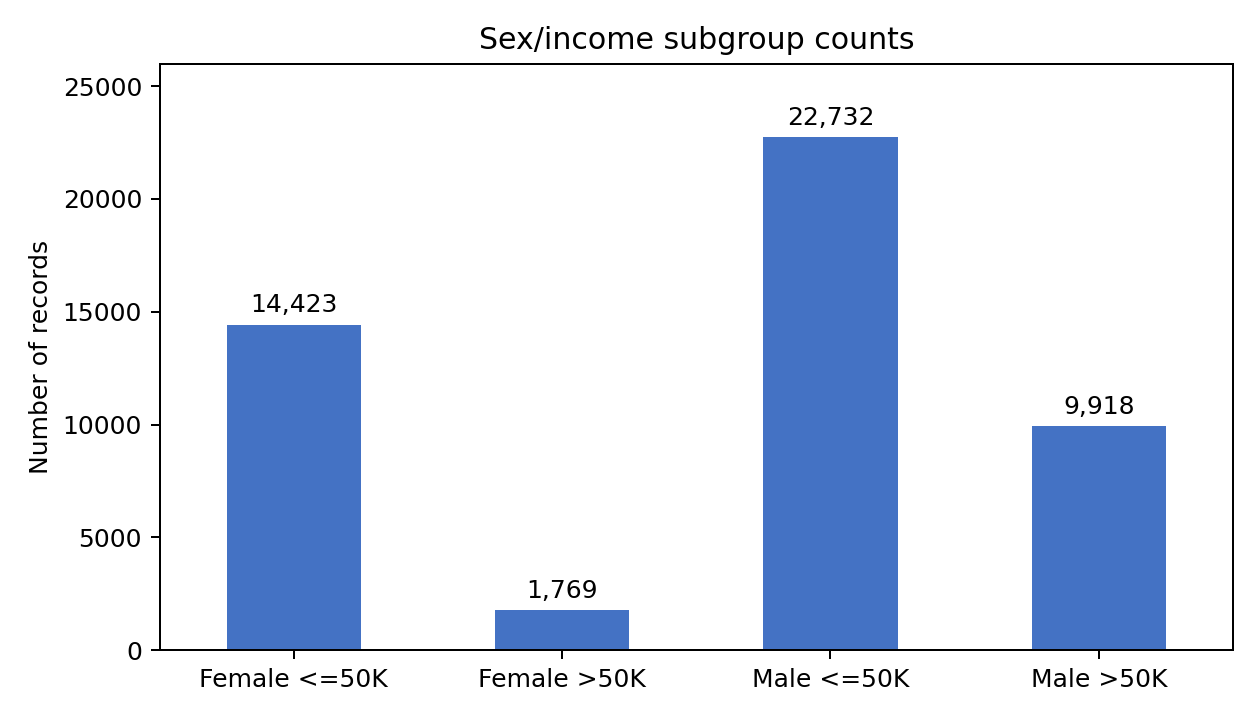

In [6]:
import matplotlib.pyplot as plt

# Plot the total counts from the table above.
sex_income_counts = summary["Total rows"]

ax = sex_income_counts.plot(kind="bar", figsize=(7, 4), color="#4472C4")
ax.set_xticklabels(["Female <=50K", "Female >50K", "Male <=50K", "Male >50K"], rotation=0)
ax.set_title("Sex/income subgroup counts")
ax.set_xlabel("")
ax.set_ylabel("Number of records")
ax.set_ylim(0, 26000)
ax.bar_label(ax.containers[0], labels=[f"{count:,}" for count in sex_income_counts], padding=3)
plt.tight_layout()
plt.show()


#### What these counts tell us

Female/>50K is the smallest subgroup with **1,769 rows**. Male/<=50K is the largest with **22,732 rows**. These counts help explain why we are comparing resampling methods. During modeling, we will calculate sampling targets separately within each training fold.

**3,620 rows** contain at least one `?`. Dropping these rows would leave **45,222 rows**, matching `adult.names`. A row with more than one unknown value is counted only once.

Dropping rows would remove **1,397 Female/<=50K**, **100 Female/>50K**, **1,744 Male/<=50K**, and **379 Male/>50K** observations. Female/>50K would remain the smallest subgroup, with **1,669 rows**. The table shows how deletion would change each subgroup's size; it does not tell us whether a model would become more or less fair.

We have not dropped or filled in any values here.


### How often is income above $50K for each sex?

There are more Male records, so counts alone do not give us a fair comparison of income rates. We calculate the percentage earning >50K within each sex and plot the results.


,Total records,Records earning >50K,Percent earning >50K
sex,,,
Female,16192,1769,10.93
Male,32650,9918,30.38


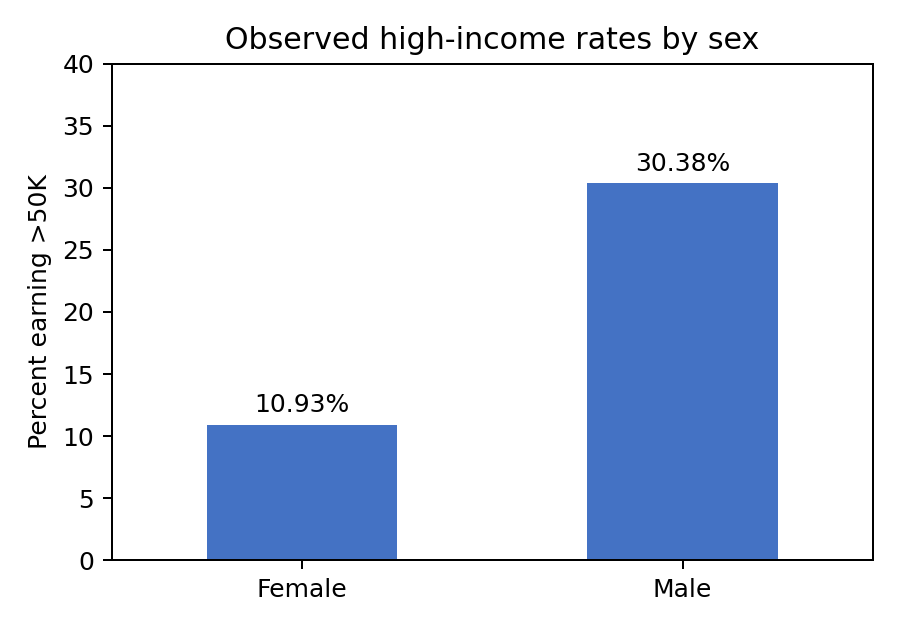

In [7]:
income_by_sex = pd.crosstab(subgroup_data["sex"], subgroup_data["income"])

income_rates = pd.DataFrame({
    "Total records": income_by_sex.sum(axis=1),
    "Records earning >50K": income_by_sex[">50K"]
})
income_rates["Percent earning >50K"] = (
    100 * income_rates["Records earning >50K"] / income_rates["Total records"]
)
display(income_rates.round(2))

ax = income_rates["Percent earning >50K"].plot(kind="bar", figsize=(5, 3.5), color="#4472C4")
ax.set_title("Observed high-income rates by sex")
ax.set_xlabel("")
ax.set_ylabel("Percent earning >50K")
ax.set_xticklabels(income_rates.index, rotation=0)
ax.set_ylim(0, 40)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.show()


#### What we found

Income is above $50K for **10.93% of Female records** and **30.38% of Male records**, a difference of about **19.45 percentage points**. Female records are fewer overall and have a lower observed high-income rate.

These are recorded incomes, not model predictions, and they do not tell us why the difference exists. In Phase 4, we will check whether resampling changes prediction rates and how often each model correctly identifies >50K records within each sex. Better overall accuracy alone will not answer those questions.


### A look at capital gain and capital loss

The earlier summaries showed that most capital gain and loss values are zero, with a few large amounts. Here we count the zero and nonzero values in the combined dataset. We also check the largest amount in each column and how many times it appears, including the capital gain value of 99,999.

These counts will help us discuss whether to keep the amounts, transform them, or replace them with yes/no indicators. This matters for SMOTE-NC because it creates new numerical values between existing observations. We only inspect the values here; we do not change them.


In [6]:
for column in ["capital_gain", "capital_loss"]:
    values = df[column]
    largest_value = values.max()

    print(f"\n{column}")
    print("Rows with zero:", (values == 0).sum())
    print("Rows with a nonzero amount:", (values > 0).sum())
    print("Largest amount:", largest_value)
    print("Rows with the largest amount:", (values == largest_value).sum())



capital_gain
Rows with zero: 44807
Rows with a nonzero amount: 4035
Largest amount: 99999
Rows with the largest amount: 244

capital_loss
Rows with zero: 46560
Rows with a nonzero amount: 2282
Largest amount: 4356
Rows with the largest amount: 3


#### What these counts tell us

**Capital gain:** 44,807 rows have zero gain and 4,035 have a positive amount. The largest amount is **99,999**, which appears in **244 rows**.

**Capital loss:** 46,560 rows have zero loss and 2,282 have a positive amount. The largest amount is **4,356**, which appears in **3 rows**.

Both columns are mostly zeros, so their overall summaries hide the smaller number of positive amounts. The repeated gain value of 99,999 is worth noting, but these counts alone do not prove that it is a cap or an error. We should not remove those rows just because their values are large.

Keeping the amounts preserves information about how much gain or loss a person has. Yes/no indicators would keep only whether an amount is positive. A log transformation would reduce the differences between large and small amounts while retaining their order.

For SMOTE-NC, we will need to inspect the generated capital amounts because values between existing observations may differ from the amounts recorded in the original data. No transformation or outlier removal has been applied in this section.


### Data quality checks and preparation

Now, before Phase 4 we need one clean version of the data that all four resampling conditions can share. We will be working on a copy called `prep` so that `df`, `adult_train` and `adult_test` stay raw for the cells above. So first lets check the labels, the duplicates and the two education columns, and then we apply the decisions we agreed previously as a team.

#### Step 1: Inconsistent labels

Copy the combined data, add a `source` column so we know which file each row came from, remove the trailing periods from the test income labels, and check that the categories match between train and test.

In [7]:
# Copy the combined data and keep track of which file each row came from
prep = df.copy()
prep["source"] = ["train"] * len(adult_train) + ["test"] * len(adult_test)

# Strip the trailing periods from the test labels
prep["income"] = prep["income"].str.rstrip(".")
assert set(prep["income"]) == {"<=50K", ">50K"}
print(prep["income"].value_counts())

# Confirm there are no extra spaces left in the string columns
text_columns = prep.select_dtypes(exclude="number").columns
extra_spaces = sum((prep[column] != prep[column].str.strip()).sum() for column in text_columns)
print(f"\nValues with extra spaces: {extra_spaces}")

# Find categories that appear in only one of the two files
is_train = prep["source"] == "train"
for column in text_columns.drop(["income", "source"]):
    train_values = set(prep.loc[is_train, column])
    test_values = set(prep.loc[~is_train, column])
    if train_values != test_values:
        print(f"{column}: train only {sorted(train_values - test_values)}, test only {sorted(test_values - train_values)}")

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

Values with extra spaces: 0
native_country: train only ['Holand-Netherlands'], test only []


#### What this tells us

After stripping the periods the income column has only two values, `37,155` rows with `<=50K` and `11,687` with `>50K`, so the train and test labels finally line up. I also checked every string column for extra spaces and found `0`, which makes sense since `skipinitialspace=True` already took care of that when loading. The only category that shows up in just one file is `Holand-Netherlands` in `native_country`, and its only in train (1 row).  
> Thats not something to fix in the data, but it does mean that maybe the encoder in Phase 4 should use `handle_unknown="ignore"` so a category that is missing from a fold or from test doesnt break anything. That is something still to be discussed.

#### Step 2: Duplicates

Check for duplicate rows in the combined data, within each file, and across the two files. I also look for conflicting rows, meaning the same 14 features but a different income, since `adult.names` mentions that there are 6 "duplicate or conflicting instances". Then I repeat the counts without `fnlwgt`, because we are dropping it and that makes more rows look identical.

In [8]:
all_columns = list(df.columns)
without_fnlwgt = [column for column in all_columns if column != "fnlwgt"]

for label, cols in [("All 15 columns", all_columns), ("Without fnlwgt", without_fnlwgt)]:
    feature_cols = [column for column in cols if column != "income"]
    train_rows = prep.loc[is_train, cols]
    test_rows = prep.loc[~is_train, cols]

    # Rows that repeat an earlier row exactly
    combined_dups = prep.duplicated(subset=cols).sum()

    # Rows with the same features but a different income
    conflicting = prep.groupby(feature_cols)["income"].transform("nunique") > 1

    print(f"\n{label}")
    print(f"Duplicate rows in the combined data: {combined_dups:,} ({combined_dups / len(prep):.1%})")
    print(f"Duplicate rows within train: {train_rows.duplicated().sum():,}")
    print(f"Duplicate rows within test: {test_rows.duplicated().sum():,}")
    # Count each distinct test row once so the three numbers add up to the combined count
    print(f"Distinct test rows that also appear in train: {len(test_rows.drop_duplicates().merge(train_rows.drop_duplicates())):,}")
    print(f"Conflicting groups: {prep.groupby(feature_cols)['income'].nunique().gt(1).sum():,}")
    print(f"Rows in conflicting groups: {conflicting.sum():,}")


All 15 columns
Duplicate rows in the combined data: 52 (0.1%)
Duplicate rows within train: 24
Duplicate rows within test: 5
Distinct test rows that also appear in train: 23
Conflicting groups: 5
Rows in conflicting groups: 10

Without fnlwgt
Duplicate rows in the combined data: 6,374 (13.1%)
Duplicate rows within train: 3,465
Duplicate rows within test: 1,022
Distinct test rows that also appear in train: 1,887
Conflicting groups: 1,029
Rows in conflicting groups: 3,873


#### What this tells us

With all 15 columns there are only `52` exact duplicate rows in the combined data (`24` within train, `5` within test, and `23` distinct test rows that also appear in train), which is roughly 0.1% of the `48,842` rows. I also found `5` conflicting groups (`10` rows) that have the same 14 features but a different income; `adult.names` says 6, so its close but not exactly the same. Without `fnlwgt` the numbers jump a lot: `6,374` duplicates (around 13%; `3,465` within train, `1,022` within test, and `1,887` distinct test rows that also appear in train) and `1,029` conflicting groups covering `3,873` rows. This actually makes sense after some thinking, since `fnlwgt` is almost unique for every row, and once its gone many people with common profiles (same age, job, 40 hours, no capital gain) look exactly the same. For now we keep all the rows, since these are separate census records and identical values can belong to different people; but because conflicting rows exist and the count without `fnlwgt` is well above 1%, I'm leaving this as an open question for the team instead of deciding it here.

#### Step 3: education vs. education_num

Cross-tabulate `education` against `education_num` to see if each education label maps to exactly one code. If it does, the two columns carry the same information and we only need one of them.

In [9]:
# Count how many codes each label uses and how many labels each code uses
education_table = pd.crosstab(prep["education"], prep["education_num"])
codes_per_label = (education_table > 0).sum(axis=1)
labels_per_code = (education_table > 0).sum(axis=0)
print(f"Most codes for one label: {codes_per_label.max()}")
print(f"Most labels for one code: {labels_per_code.max()}")
assert codes_per_label.max() == 1 and labels_per_code.max() == 1

# Show the mapping sorted by code
display(prep[["education", "education_num"]].drop_duplicates().sort_values("education_num").reset_index(drop=True))

# Keep the ordered numeric code and drop the text label
prep = prep.drop(columns="education")

Most codes for one label: 1
Most labels for one code: 1


,education,education_num
0,Preschool,1
1,1st-4th,2
2,5th-6th,3
3,7th-8th,4
4,9th,5
5,10th,6
6,11th,7
7,12th,8
8,HS-grad,9
9,Some-college,10


#### What this tells us

The crosstab is one-to-one: every education label has exactly one code and every code has exactly one label, going from `Preschool` = 1 up to `Doctorate` = 16. So basically `education_num` is just `education` written as an ordered number, which is why we dropped `education` and kept `education_num`; no information is lost and the tree can split on the order directly. One thing to remember for Phase 4 is that SMOTE-NC will interpolate `education_num` like any other number, so it can create values like `12.4`; so we either need to round the synthetic values to the nearest valid integer (1 to 16), or tell SMOTE-NC to treat education_num as categorical so it only copies real values; we'll decide that in Phase 4.

#### Step 4: Apply the agreed decisions

Replace `?` with `Unknown`, drop `fnlwgt`, and log transform the two capital columns. We keep the rows with `?` and give them their own category, since dropping them would shrink the subgroups (Female >50K would lose `100` rows) and we would rather not guess values. We drop `fnlwgt` because its a census sampling weight, not a trait of the person, and it is only comparable within a state, which we dont have. And finally we use `np.log1p` on the capital columns so the huge amounts (like `99,999`) dont dominate the distances SMOTE-NC uses to pick neighbors. All of this is the same for the 4 resampling conditions.

In [10]:
import numpy as np

# Replace the ? markers with their own Unknown category
unknown_cols = ["workclass", "occupation", "native_country"]
prep[unknown_cols] = prep[unknown_cols].replace("?", "Unknown")
print(prep[unknown_cols].eq("Unknown").sum())
assert not prep.eq("?").any().any()

# Drop the census sampling weight
prep = prep.drop(columns="fnlwgt")

# Log transform the capital columns, then drop the raw amounts
for column in ["capital_gain", "capital_loss"]:
    prep[f"{column}_log"] = np.log1p(prep[column])
display(prep[["capital_gain", "capital_gain_log", "capital_loss", "capital_loss_log"]].agg(["min", "max"]).round(3))
prep = prep.drop(columns=["capital_gain", "capital_loss"])

workclass         2799
occupation        2809
native_country     857
dtype: int64


,capital_gain,capital_gain_log,capital_loss,capital_loss_log
min,0,0.000,0,0.00
max,99999,11.513,4356,8.38


#### What this tells us

The `Unknown` category now has `2,799` rows in `workclass`, `2,809` in `occupation`, and `857` in `native_country`, the same as the `?` counts from earlier, and no `?` is left anywhere. After the log transform `capital_gain` goes from 0 to 99,999 down to 0 to roughly `11.51`, and `capital_loss` from 0 to 4,356 down to 0 to around `8.38`; zeros stay zeros, so the zero vs. positive split and the order of the amounts are both kept. I was actually tempted to also remove outliers like age 90, 1 or 99 hours per week, or the 99,999 gain; but we decided not to, since they are plausible recorded values, a decision tree splits on thresholds so extreme values dont pull it the way they would pull a linear model, and the log transform already takes care of the capital tail.

#### Step 5: Final prepared dataset

Put the columns in order, list the predictors and the target, and run a few final checks to make sure we didnt lose any rows or change the subgroup counts.

In [11]:
numerical = ["age", "education_num", "capital_gain_log", "capital_loss_log", "hours_per_week"]
categorical = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
target = "income"

# Make sure no column was missed, then put them in a fixed order
assert sorted(prep.columns) == sorted(numerical + categorical + [target, "source"])
prep = prep[numerical + categorical + [target, "source"]]

print(f"Shape: {prep.shape[0]:,} rows, {prep.shape[1]} columns")
print(f"Numerical predictors: {numerical}")
print(f"Categorical predictors: {categorical}")
print(f"Target: {target}")
print("Helper column: source")
display(prep.dtypes.to_frame("dtype"))
display(prep.head())

# Final checks
assert len(prep) == 48842
assert not prep.eq("?").any().any()
assert prep["income"].nunique() == 2

subgroups = prep.groupby(["sex", "income"]).size()
display(subgroups.to_frame("rows"))
assert subgroups.to_dict() == {
    ("Female", "<=50K"): 14423,
    ("Female", ">50K"): 1769,
    ("Male", "<=50K"): 22732,
    ("Male", ">50K"): 9918
}

Shape: 48,842 rows, 14 columns
Numerical predictors: ['age', 'education_num', 'capital_gain_log', 'capital_loss_log', 'hours_per_week']
Categorical predictors: ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Target: income
Helper column: source


,dtype
age,int64
education_num,int64
capital_gain_log,float64
capital_loss_log,float64
hours_per_week,int64
workclass,str
marital_status,str
occupation,str
relationship,str
race,str


,age,education_num,capital_gain_log,capital_loss_log,hours_per_week,workclass,marital_status,occupation,relationship,race,sex,native_country,income,source
0,39,13,7.684784,0.0,40,State-gov,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K,train
1,50,13,0.000000,0.0,13,Self-emp-not-inc,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K,train
2,38,9,0.000000,0.0,40,Private,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K,train
3,53,7,0.000000,0.0,40,Private,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K,train
4,28,13,0.000000,0.0,40,Private,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K,train


rows
sex    income       
Female <=50K   14423
       >50K     1769
Male   <=50K   22732
       >50K     9918

#### What this tells us

The prepared data has `48,842` rows and 14 columns: 5 numerical predictors, 7 categorical predictors, the `income` target, and the `source` helper column. All the asserts passed, so no rows were lost, no `?` is left, income has just 2 values, and the subgroup counts are the same as before (Female <=50K `14,423`, Female >50K `1,769`, Male <=50K `22,732`, Male >50K `9,918`). `sex` stays in the data because we need it for the subgroups and the fairness metrics; whether its also an input to the classifier is still an open Phase 4 decision, so I didnt decide that here.

#### Summary of the preparation steps

| Step | What we did | Why |
| --- | --- | --- |
| Income labels | Removed the trailing `.` from the test labels | So train and test use the same two values, `<=50K` and `>50K` |
| Whitespace | Checked all string columns; nothing to fix | `skipinitialspace=True` already cleaned them when loading |
| Category sets | Compared train and test; only `Holand-Netherlands` is train only | The Phase 4 encoder should use `handle_unknown="ignore"` |
| Duplicates | Counted them and kept all rows for now | Separate census records can share values; the conflicting rows and the count without `fnlwgt` are an open question |
| Education | Dropped `education`, kept `education_num` | One-to-one mapping, so no information is lost; synthetic values need rounding in Phase 4 |
| Missing values | Replaced `?` with `Unknown` in `workclass`, `occupation`, `native_country` | Keeps all 3,620 rows and the subgroup sizes, and avoids guessing values |
| `fnlwgt` | Dropped it | Census sampling weight, not a personal trait, and only comparable within a state |
| Capital gain and loss | Replaced with `np.log1p` versions | Keeps the zeros and the order but reduces the pull of large values on SMOTE-NC neighbors |
| Outliers | Kept them | Plausible values; the tree splits on thresholds and the log already handles the capital tail |
| Train/test split | Kept the supplied split with a `source` column | CV folds within train, and test reserved for the final evaluation |